# Problem Sheet 2

In [16]:
import numpy as np
import matplotlib.pyplot as plt

## 2.1

### a)

$f[x_0] = f(0) = 1$

$f[x_1] = f(1) = \frac{1}{2}$

$f[x_2] = f(2) = \frac{1}{3}$

$f[x_0, x_1] = \frac{\frac{1}{2} - 1}{1 - 0} = -\frac{1}{2}$

$f[x_1, x_2] = \frac{\frac{1}{3} - \frac{1}{2}}{2 - 1} = -\frac{1}{6}$

$f[x_0, x_1, x_2] = \frac{-\frac{1}{6}+\frac{1}{2}}{2-0} = \frac{1}{6}$

$$
\begin{aligned}
p_2(x) &=1 - \frac{1}{2}\cdot(x - 0) + \frac{1}{6}\cdot(x - 0) \cdot (x - 1)\\
&= 1 - \frac{1}{2} \cdot x + \frac{1}{6}\cdot x \cdot(x - 1)
\end{aligned}
$$

$f[x_3] = f(4) = \frac{1}{5}$

$f[x_2, x_3] = \frac{\frac{1}{5} - \frac{1}{3}}{4 - 2} = -\frac{1}{15}$

$f[x_1,x_2,x_3] = \frac{-\frac{1}{15} + \frac{1}{6}}{4 - 1} = \frac{1}{30}$

$f[x_0, x_1, x_2, x_3] = \frac{\frac{1}{30} - \frac{1}{6}}{4 - 0} = -\frac{1}{30}$

$$
\begin{aligned}
p_3(x) &= 1 - \frac{1}{2}\cdot(x - 0) + \frac{1}{6}\cdot(x - 0) \cdot (x - 1) - \frac{1}{20} \cdot (x - 0) \cdot (x - 1) \cdot (x - 2)\\
&= 1 - \frac{1}{2} \cdot x + \frac{1}{6}\cdot x \cdot(x - 1) - \frac{1}{30} \cdot x \cdot (x - 1) \cdot (x - 2)
\end{aligned}
$$


### b)

$$
\begin{aligned}
p_3(x) &= 1 + (x-0) \cdot \left(-\frac{1}{2} + (x-1) \cdot \left(\frac{1}{6} + (x-2) \cdot  \frac{1}{30} \right)\right)\\
&= 1 + x \cdot \left(-\frac{1}{2} + (x-1) \cdot \left(\frac{1}{6} + (x-2) \cdot  \frac{1}{30} \right)\right)
\end{aligned}
$$

$$
\begin{aligned}
|f(x) - p_3(3)| &= \left|\frac{1}{1+3} - \left(1 + 3 \cdot \left(-\frac{1}{2} + (3-1) \cdot \left(\frac{1}{6} + (3-2) \cdot  \frac{1}{30} \right)\right)\right)\right|\\
&=\frac{27}{60} = 0.45
\end{aligned}
$$

In [17]:
def f(x):
    return 1 / (1+x)

def p_3(x):
    return 1 + x * (-.5 + (x-1) * (1/6 + (x-2) / 30))

def error(x):
    return abs(f(x)-p_3(x))

error(3)

0.44999999999999996

### c)

In [28]:
def find_coefficients(x_knots, f_knots):
    divided_differences = np.ndarray((len(f_knots), len(x_knots)))

    coefficients = []

    for column_index in range(len(x_knots)):
        for row_index in range(len(f_knots)-column_index):
            if column_index == 0:
                divided_differences[row_index, column_index] = f_knots[row_index]
            else:
                divided_differences[row_index, column_index] = (divided_differences[row_index + 1, column_index-1] - divided_differences[row_index, column_index - 1]) / (x_knots[row_index+column_index] - x_knots[row_index])

            if row_index == 0:
                coefficients.append(divided_differences[row_index, column_index])

    return coefficients


def find_approximation(x_knots, f_knots):
    coefficients = find_coefficients(x_knots, f_knots)
    print(f'coefficients = {np.round(coefficients, 3)}')
    def p(evaluation_point):
        result = coefficients[-1]
        for i in range(len(x_knots)-1, -1, -1):
            result = coefficients[i] + (evaluation_point - x_knots[i]) * result

        return result

    return p

In [29]:
x_knots = np.array([0, 1, 2, 4])
f_knots = np.array([1, 1/2, 1/3, 1/5])

p = find_approximation(x_knots, f_knots)
knot_values =  [p(0), p(1), p(2), p(4)]
print(f'knot values = {np.round(knot_values, 3)}')

coefficients = [ 1.    -0.5    0.167 -0.033]
knot values = [1.    0.5   0.333 0.2  ]


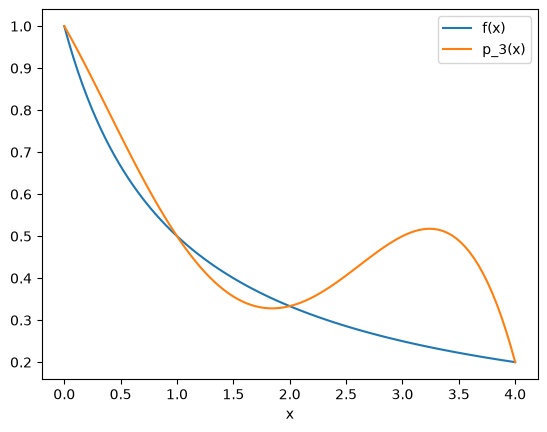

In [22]:
x_plot = list(np.linspace(0, 4, 100))
p_plot = [p(x_i) for x_i in x_plot]
f_plot = [f(x_i) for x_i in x_plot]

fix, ax = plt.subplots()
ax.plot(x_plot, f_plot, label='f(x)')
ax.plot(x_plot, p_plot, label='p_3(x)')
ax.set_xlabel("x")
ax.legend()

In [32]:
x_sampling = np.linspace(0, 4, 1001)
max_error = max([abs(p(x_i) - f(x_i)) for x_i in x_sampling])
print(f'max_error = {np.round(max_error, 4)}')

max_error = 0.2838
